### Test for member-metabolite interaction predictions

In [16]:
import numpy as np
import pandas as pd

import sys
sys.path.append("../functions/")

import compare_met_exp_sim.correlation as correlation

In [17]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


[INFO] make_scatterplot removes nan values in 'simulated' column for scatterplot and uses all values for density plot.
[INFO] merge_sim_exp removes compounds not in experimental data
[INFO] find_correlation uses dropna() to for missing entries in simulations that exist in experimental results.
[INFO] merge_sim_exp removes compounds not in experimental data


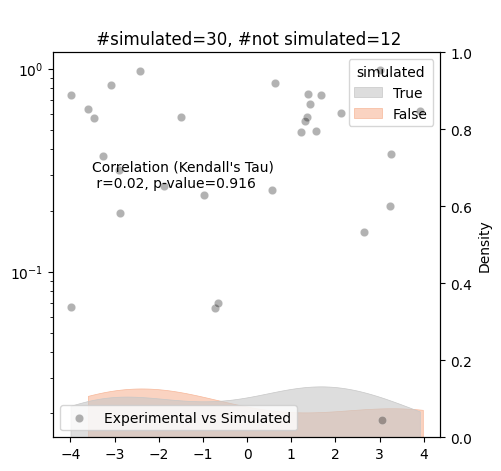

In [18]:
np.random.seed(1)
signal_exp_example_dict = {(f"member_{np.random.randint(0,10)}",f"met_{np.random.randint(0,10)}"):np.random.uniform(-4,4) for _ in range(50)}
signal_exp_example = pd.Series(signal_exp_example_dict)
signal_exp_example.index.names = ["member","met_group"]
signal_exp_example.name = "experimental"

n_size = 30
membs_mets = np.random.choice(signal_exp_example.index,replace=False,size=n_size)
members=[member for member,_ in membs_mets]
mets=[met for _,met in membs_mets]
simulation_values_uniform = [np.random.uniform(0,1) for _ in range(n_size)]

simulation_res_uniform = pd.DataFrame({"receiver":members,
              "met_group":mets,
              "metric":simulation_values_uniform})


func = lambda x: (x**2)/10
simulation_values_corr = [func(value) for _,value in signal_exp_example.items() if value<0]
simulation_res_corr = pd.DataFrame({"receiver":[member for (member,_),value in signal_exp_example.items() if value<0],
              "met_group":[met for (_,met),value in signal_exp_example.items() if value<0],
              "metric":simulation_values_corr})

#simulation_dict_example = {"receiver":{"simulation_method":{"uniform":simulation_res_uniform,
#                                                            "correlated":simulation_res_corr}}}

fig,ax,ax_twin=correlation.make_scatterplot(simulation_res_uniform, 
                             signal_exp_example,
                             receiver_or_donor="receiver",
                             metric="metric",
                             agg_method="sum",
                            met_column="met_group",
                            ax=None,
                            verbose=True,
                            legend=True)


[INFO] make_scatterplot removes nan values in 'simulated' column for scatterplot and uses all values for density plot.
[INFO] merge_sim_exp removes compounds not in experimental data
[INFO] find_correlation uses dropna() to for missing entries in simulations that exist in experimental results.
[INFO] merge_sim_exp removes compounds not in experimental data


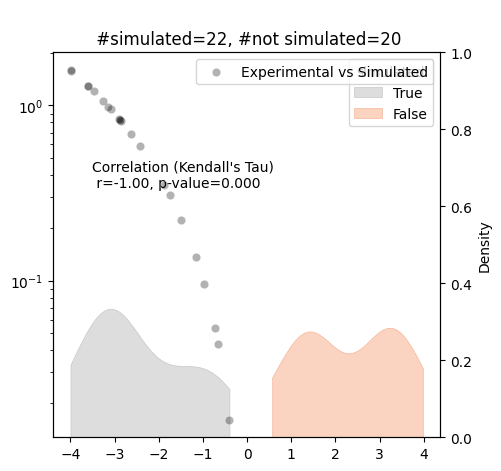

In [19]:

fig,ax,ax_twin=correlation.make_scatterplot(simulation_res_corr, 
                             signal_exp_example,
                             receiver_or_donor="receiver",
                             metric="metric",
                             agg_method="sum",
                            met_column="met_group",
                            ax=None,
                            verbose=True,
                            legend=True)


### Test for member-member interaction predictions

<img src="IMG_3818.png" width="500"/>

In [ ]:
import pandas as pd
import numpy as np
import sys

sys.path.append("../functions/")

sys.path.append("../functions/")

import compare_inter_exp_sim.correlation as correlation


In [2]:
%load_ext autoreload
%autoreload 2

In [ ]:
simulated_test = pd.DataFrame(
    {"donor": ["environment","C","C","environment"],
 "receiver":["C","A","B","B"],
 "compound":["c2","c3","c3","c3"],
"metric":[1.0,1,1.0,1.0]})
simulated_test

,donor,receiver,compound,metric
0,environment,C,c2,1.0
1,C,A,c3,1.0
2,C,B,c3,1.0
3,environment,B,c3,1.0


In [ ]:
exp_signal_test = pd.Series({("A","B"):1,
                            ("A","C"):1,
                             ("B","A"):1,
                             ("B","C"):1,
                             ("C","A"):1,
                             ("C","B"):1})
exp_signal_test.index.names = ["member_second","member_main"]
exp_signal_test.name = "experimental"
exp_signal_test

member_second  member_main
A              B              1
               C              1
B              A              1
               C              1
C              A              1
               B              1
Name: experimental, dtype: int64

In [ ]:
correlation._merge_exp_sim(simulated_test,exp_signal_test,coop_or_comp="coop",metric="metric")

experimental  simulated  Was simulated
member_second member_main                                        
A             B                       1        NaN          False
              C                       1        NaN          False
B             A                       1        NaN          False
              C                       1        NaN          False
C             A                       1        1.0           True
              B                       1        0.5           True

In [ ]:
correlation._merge_exp_sim(simulated_test,exp_signal_test,coop_or_comp="comp",metric="metric")

experimental  simulated  Was simulated
member_second member_main                                        
A             B                       1        1.0           True
              C                       1        0.0           True
B             A                       1        1.0           True
              C                       1        0.0           True
C             A                       1        0.0           True
              B                       1        0.0           True

### Abundances

In [21]:
import abundance_sim_analysis

In [22]:
abundances_example = pd.DataFrame([
    {"sample":1,"member":"A","relative_abundance":0.4,"community":"test"},
    {"sample":1,"member":"B","relative_abundance":0.6,"community":"test"},
    {"sample":2,"member":"A","relative_abundance":1,"community":"test"},
    {"sample":3,"member":"B","relative_abundance":0.3,"community":"test"},
    {"sample":3,"member":"C","relative_abundance":0.7,"community":"test"},
    {"sample":4,"member":"C","relative_abundance":0.4,"community":"test"},
    {"sample":4,"member":"B","relative_abundance":0.6,"community":"test"}])

In [23]:
abundances_example

,sample,member,relative_abundance,community
0,1,A,0.4,test
1,1,B,0.6,test
2,2,A,1.0,test
3,3,B,0.3,test
4,3,C,0.7,test
5,4,C,0.4,test
6,4,B,0.6,test


In [24]:
co_growth_count,member_abund = abundance_sim_analysis.make_co_growth_count_matrix(abundances_example,community="test")

[INFO] Make_co_growth_count_matrix sets diagonal entries (memberA==memberB) to 0.


In [25]:
abundance_sim_analysis.order_co_growth_count(co_growth_count)

['B', 'A', 'C']

<Axes: title={'center': 'test'}, xlabel='member2', ylabel='member1'>

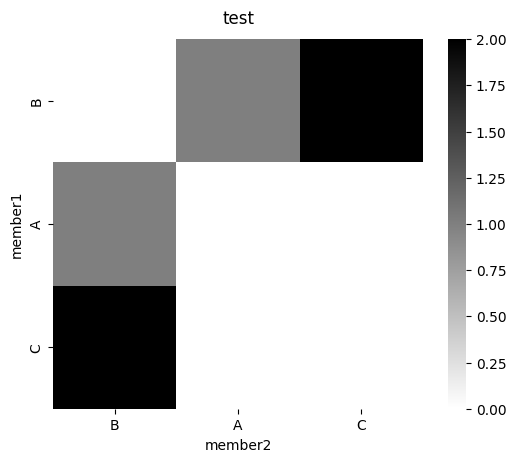

In [26]:


abundance_sim_analysis.plot_co_growth_count(co_growth_count,"test")

<Axes: title={'center': 'test: co_growth'}, xlabel='# members in same sample', ylabel='# samples'>

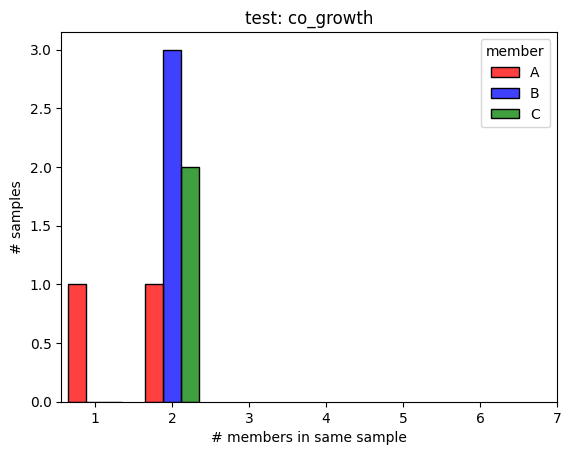

In [27]:
import matplotlib.pyplot as plt

palette = {"A":"red","B":"blue","C":"green"}

fig,ax = plt.subplots(1,1)
abundance_sim_analysis.plot_hist_helper(abundances_example,"test",['A','B','C'],"co_growth",palette,ax)

<Axes: title={'center': 'test: co_growth'}, xlabel='Relative abundance', ylabel='Density'>

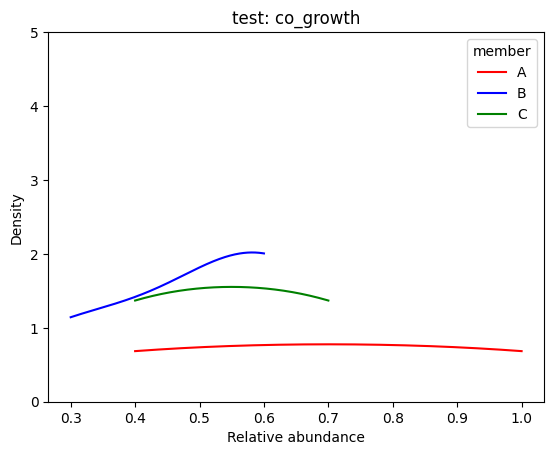

In [28]:
fig,ax = plt.subplots(1,1)
abundance_sim_analysis.plot_density_helper(abundances_example,"test",['A','B','C'],"co_growth",palette,ax)

In [5]:
from reframed import Environment,FBA, Community
from reframed.community.solution import CommunitySolution
import sys
import pandas as pd
sys.path.append("../functions/")
import general

In [4]:
models = general.load_models_guillen2021(all_38_strains=False)

INFO     | Loading models from Guillen et al (2021)...


In [10]:
media_db = pd.read_csv("https://raw.githubusercontent.com/cdanielmachado/carveme/5b25ce504de41060fb5dbaf4c87e13627c650632/carveme/data/input/media_db.tsv",sep="\t")
lb_mets = media_db.query("medium=='LB'").compound.values
env_lb = Environment.from_compounds(lb_mets)

comm = Community(models=models.values(),community_id="test")

env_lb.apply(comm.merged_model,inplace=True,exclusive=True)

/Users/idunmariaburgos/SteadierCom/reframed/reframed/core/environment.py:75: UserWarning: Exchange reaction not in model: R_EX_cro4_e
  warn(f'Exchange reaction not in model: {r_id}')
/Users/idunmariaburgos/SteadierCom/reframed/reframed/core/environment.py:75: UserWarning: Exchange reaction not in model: R_EX_fol_e
  warn(f'Exchange reaction not in model: {r_id}')
/Users/idunmariaburgos/SteadierCom/reframed/reframed/core/environment.py:75: UserWarning: Exchange reaction not in model: R_EX_ribflv_e
  warn(f'Exchange reaction not in model: {r_id}')


In [11]:
sol = FBA(comm.merged_model)
comm_sol = CommunitySolution(community=comm,values=sol.values)


Set parameter Username


INFO     | Set parameter Username


Academic license - for non-commercial use only - expires 2026-03-27


INFO     | Academic license - for non-commercial use only - expires 2026-03-27


In [17]:
sys.getsizeof(comm_sol.cross_feeding(as_df=True))

42972

In [18]:
sys.getsizeof(comm_sol.cross_feeding())

1848

In [20]:
df1 = comm_sol.cross_feeding(as_df=True)

In [21]:
df2 = comm_sol.cross_feeding(as_df=True)

In [22]:
df1

,donor,receiver,compound,rate,mass_rate
0,mutant_panZ,mutant_icd,M_co2_e,1.107611,0.048745
1,mutant_panZ,mutant_panD,M_co2_e,0.303145,0.013341
2,mutant_panZ,None,M_co2_e,7.728912,0.340146
3,mutant_bioF,mutant_icd,M_co2_e,0.435646,0.019173
4,mutant_bioF,mutant_panD,M_co2_e,0.119233,0.005247
...,...,...,...,...,...
212,None,mutant_icd,M_h2o_e,2.634797,0.047466
213,None,mutant_bioH,M_h2o_e,1.168003,0.021042
214,None,mutant_cysW,M_h2o_e,6.197034,0.111641
215,None,mutant_panD,M_uri_e,10.000000,2.442009


In [23]:
pd.concat([df1,df2])

,donor,receiver,compound,rate,mass_rate
0,mutant_panZ,mutant_icd,M_co2_e,1.107611,0.048745
1,mutant_panZ,mutant_panD,M_co2_e,0.303145,0.013341
2,mutant_panZ,None,M_co2_e,7.728912,0.340146
3,mutant_bioF,mutant_icd,M_co2_e,0.435646,0.019173
4,mutant_bioF,mutant_panD,M_co2_e,0.119233,0.005247
...,...,...,...,...,...
212,None,mutant_icd,M_h2o_e,2.634797,0.047466
213,None,mutant_bioH,M_h2o_e,1.168003,0.021042
214,None,mutant_cysW,M_h2o_e,6.197034,0.111641
215,None,mutant_panD,M_uri_e,10.000000,2.442009
